
# Task 5: Deep Learning / NLP Text Classifier

## Sentiment Analysis Using PyTorch

**Dataset:** IMDb Movie Reviews  
**Task:** Binary sentiment classification  
**Classes:** Negative (0) and Positive (1)  
**Feature Extraction:** TF-IDF  
**Deep Learning Framework:** PyTorch

### Model architecture
- Input: TF-IDF features
- Dense layer: 256 neurons
- Batch Normalization, ReLU, Dropout
- Dense layer: 128 neurons
- Batch Normalization, ReLU, Dropout
- Output layer: 1 neuron with sigmoid probability

### Training techniques
- Adam optimizer
- Binary Cross-Entropy with Logits
- Validation-based early stopping
- Separate test-set evaluation


In [13]:

from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

import torch
import torch.nn as nn
import joblib

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

MODEL_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs"

print("Project:", ROOT)
print("PyTorch:", torch.__version__)
print("Model exists:", (MODEL_DIR / "sentiment_model.pth").exists())
print("Vectorizer exists:", (MODEL_DIR / "tfidf_vectorizer.joblib").exists())


Project: c:\Users\Atharva Joshi\OneDrive\Documents\RabTech_Task5_DeepLearning_NLP
PyTorch: 2.14.1+cpu
Model exists: True
Vectorizer exists: True


In [14]:

metrics_path = OUTPUT_DIR / "test_metrics.json"

with open(metrics_path, "r", encoding="utf-8") as file:
    metrics = json.load(file)

metrics_df = pd.DataFrame(
    [{"Metric": name.replace("_", " ").title(),
      "Score": round(value, 4),
      "Percentage": f"{value * 100:.2f}%"}
     for name, value in metrics.items()]
)

display(metrics_df)


,Metric,Score,Percentage
0,Accuracy,0.8884,88.84%
1,Precision,0.8980,89.80%
2,Recall,0.8765,87.65%
3,F1 Score,0.8871,88.71%
4,Roc Auc,0.9581,95.81%


In [15]:

report_path = OUTPUT_DIR / "classification_report.txt"
print(report_path.read_text(encoding="utf-8"))


Test Set Classification Report

              precision    recall  f1-score   support

    Negative       0.88      0.90      0.89     12500
    Positive       0.90      0.88      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000

Metrics:
{
    "accuracy": 0.88844,
    "precision": 0.8979591836734694,
    "recall": 0.87648,
    "f1_score": 0.8870895915145136,
    "roc_auc": 0.9580563808
}


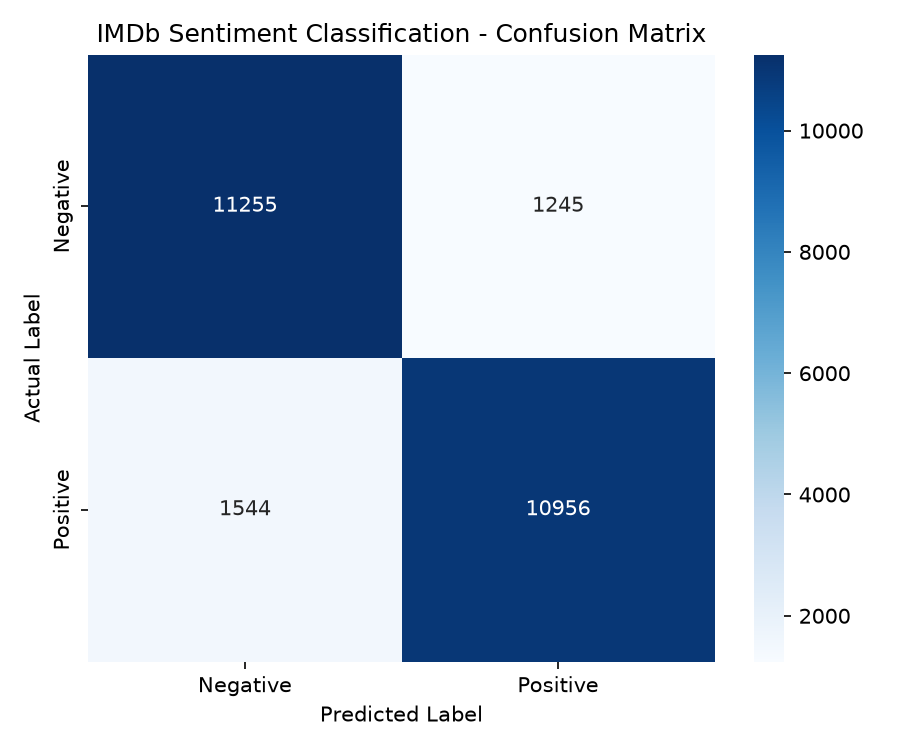

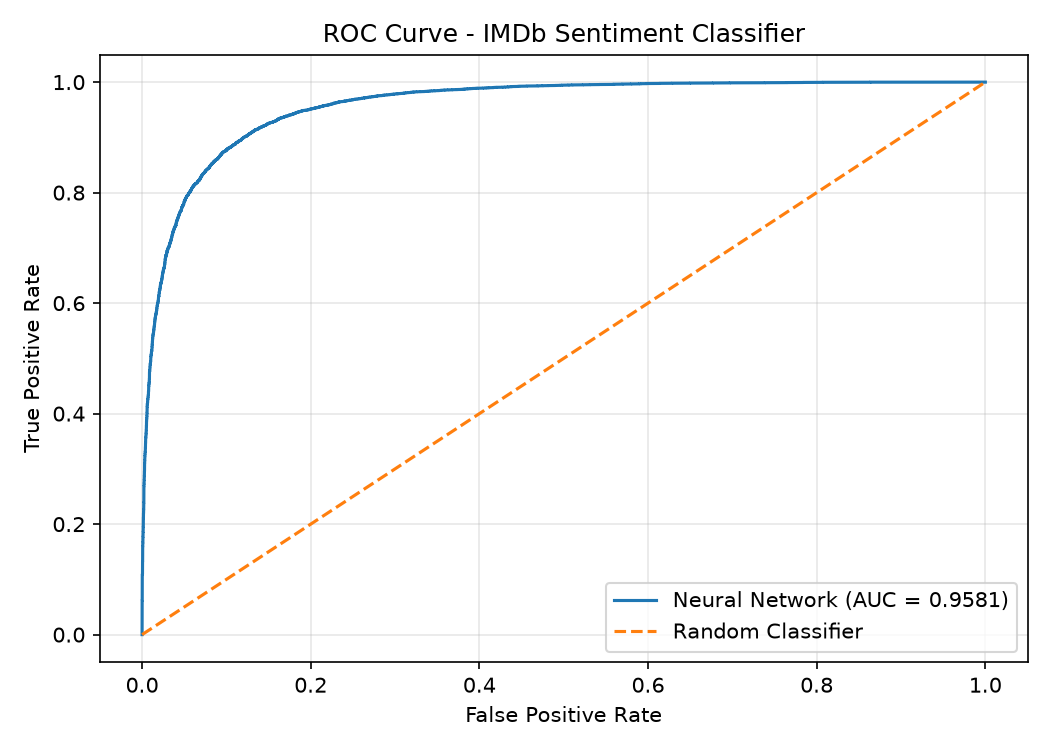

In [16]:

display(Image(filename=str(OUTPUT_DIR / "confusion_matrix.png")))
display(Image(filename=str(OUTPUT_DIR / "roc_curve.png")))


In [17]:

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with open(MODEL_DIR / "model_config.json", "r", encoding="utf-8") as file:
    config = json.load(file)

vectorizer = joblib.load(MODEL_DIR / "tfidf_vectorizer.joblib")


class SentimentClassifier(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(128, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


model = SentimentClassifier(config["input_size"]).to(DEVICE)
state = torch.load(
    MODEL_DIR / "sentiment_model.pth",
    map_location=DEVICE,
    weights_only=True,
)
model.load_state_dict(state)
model.eval()

print("Trained model loaded successfully.")


Trained model loaded successfully.


In [18]:

def predict_sentiment(reviews):
    features = vectorizer.transform(reviews)
    results = []

    model.eval()
    with torch.no_grad():
        for start in range(0, len(reviews), 128):
            batch = features[start:start + 128].toarray()
            x = torch.tensor(batch, dtype=torch.float32, device=DEVICE)
            probabilities = torch.sigmoid(model(x)).cpu().numpy()

            for review, probability in zip(
                reviews[start:start + 128], probabilities
            ):
                sentiment = "Positive" if probability >= 0.5 else "Negative"
                confidence = max(float(probability), 1 - float(probability))

                results.append({
                    "Review": review,
                    "Predicted Sentiment": sentiment,
                    "Positive Probability": round(float(probability), 4),
                    "Confidence (%)": round(confidence * 100, 2),
                })

    return pd.DataFrame(results)


unseen_reviews = [
    "This movie was wonderful, emotional, and beautifully acted.",
    "The film was boring, poorly written, and a complete waste of time.",
    "The acting was good, but the story was predictable.",
    "An outstanding film with an engaging story and excellent performances.",
    "I disliked the movie because it was dull and disappointing.",
]

display(predict_sentiment(unseen_reviews))


,Review,Predicted Sentiment,Positive Probability,Confidence (%)
0,"This movie was wonderful, emotional, and beaut...",Positive,0.9872,98.72
1,"The film was boring, poorly written, and a com...",Negative,0.0023,99.77
2,"The acting was good, but the story was predict...",Negative,0.2515,74.85
3,An outstanding film with an engaging story and...,Positive,0.9399,93.99
4,I disliked the movie because it was dull and d...,Negative,0.0075,99.25



## Conclusion

A multilayer neural network was developed using PyTorch to classify IMDb movie reviews as positive or negative. TF-IDF was used for text representation, while Batch Normalization, Dropout, and validation-based Early Stopping were incorporated during training.

The model was evaluated on a separate test set using Accuracy, Precision, Recall, F1-Score, and ROC-AUC. Training curves, a confusion matrix, a ROC curve, a classification report, and predictions on unseen text were generated.

The trained model and TF-IDF vectorizer were saved for reuse.
